# 06 · Insights and Recommendations
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**Purpose.** Translate the statistical and machine-learning evidence into findings a **stakeholder** can act on. This is the "so what?" notebook.

**Stakeholder (hypothetical).** A state education department or education foundation deciding where to direct funding and support across K-12 schools.

**Primary question.**
> After accounting for socioeconomic conditions, are per-pupil expenditure and broadband access still associated with mathematics proficiency in US K-12 schools?

> **How this notebook works.** Every number below is read from the results saved by notebooks 04 and 05 (`reports/results/*.json`) or computed from the cleaned data. Nothing is typed in by hand, so the text cannot drift out of sync with the analysis. If you re-run the earlier notebooks, this one updates itself.

**Contents**
1. Load the evidence
2. The headline answer
3. Five insights (meaning, evidence, explanations, limitations, what to investigate next)
4. Recommendations (finding, evidence, recommendation, expected impact, caveat)
5. Limitations of the whole project
6. Conclusion
7. Reflection template

## 1. Load the evidence

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from utils import PATHS, set_style, save_fig, load_json, PALETTE
from data_cleaning import load_k12
set_style()

S = load_json('stats_results')
M = load_json('ml_results')
k12 = load_k12()

bb_q1, bb_q3 = k12['broadband_access_pct'].quantile([.25, .75])

# Convenient shortcuts
m1, m2, m3, m4 = (S['models'][m] for m in ['M1', 'M2', 'M3', 'M4'])
ppe_raw, ppe_adj = m1['ppe'][0], m3['ppe'][0]
bb = m3['bb']
corr = S['corr']
n = S['n']
sel = M['selected_test']
H = M['headline']
abl = pd.DataFrame(M['ablation']).set_index('feature set')

# Poverty gap: mean math proficiency in the lowest vs highest poverty third of schools
tert = k12.groupby('poverty_tertile', observed=True)['math_proficiency_pct'].mean()
pov_gap = tert['Low poverty'] - tert['High poverty']
ppe_sd = k12['ppe_k'].std()
print(f'Evidence loaded: {n:,} K-12 schools | selected ML model: {M["selected_model"]}')

Evidence loaded: 4,642 K-12 schools | selected ML model: Linear regression


## 2. The headline answer

The chart contrasts each factor's **raw** association with math proficiency against its **adjusted** association (after the other variables, especially poverty, are held fixed). All values are on a standardised scale (1 sd), so they can be compared directly.

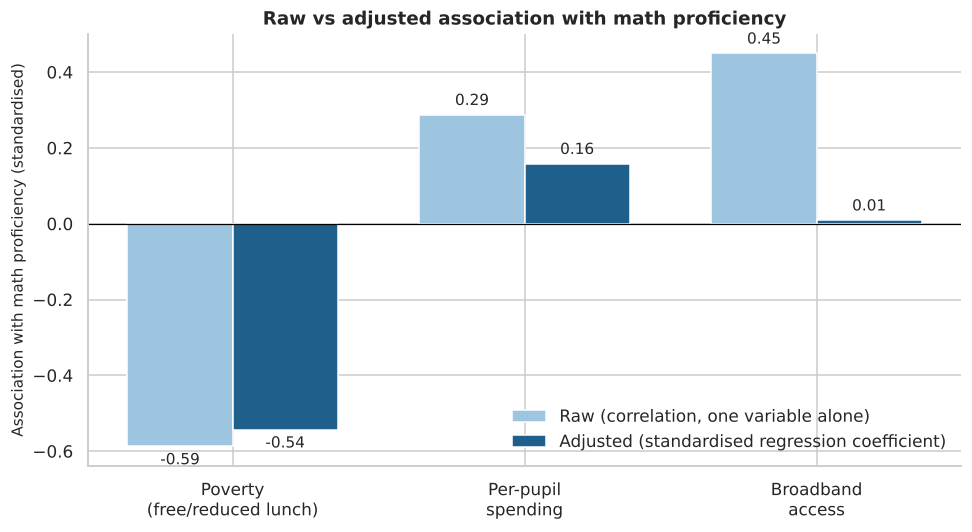


**Answer to the primary question.**
- **Per-pupil spending: yes, still associated.** The raw association shrinks (from 1.25 to 0.69 points per extra $1,000) but remains clearly positive after accounting for poverty.
- **Broadband access: no, not once poverty is accounted for.** Its raw correlation (r = 0.45) shrinks to an adjusted coefficient of 0.033 points per percentage point, whose confidence interval (-0.09 to 0.16) includes zero.
- **Poverty is the dominant factor** in every analysis.


In [2]:
labels = ['Poverty\n(free/reduced lunch)', 'Per-pupil\nspending', 'Broadband\naccess']
raw_vals = [corr['percent_free_reduced_lunch']['pearson'], corr['ppe_k']['pearson'], corr['broadband_access_pct']['pearson']]
adj_vals = [S['std_beta']['frl'], S['std_beta']['ppe'], S['std_beta']['bb']]

x = np.arange(3); w = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w / 2, raw_vals, w, label='Raw (correlation, one variable alone)', color='#9ec5e0')
b2 = ax.bar(x + w / 2, adj_vals, w, label='Adjusted (standardised regression coefficient)', color=PALETTE['primary'])
ax.axhline(0, color='black', lw=.8)
for bars in (b1, b2):
    for r in bars:
        h = r.get_height()
        ax.annotate(f'{h:.2f}', (r.get_x() + r.get_width() / 2, h), ha='center', va='bottom' if h >= 0 else 'top',
                    xytext=(0, 4 if h >= 0 else -4), textcoords='offset points', fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Association with math proficiency (standardised)')
ax.set_title('Raw vs adjusted association with math proficiency')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); save_fig('06_headline_raw_vs_adjusted'); plt.show()

display(Markdown(f'''
**Answer to the primary question.**
- **Per-pupil spending: yes, still associated.** The raw association shrinks (from {ppe_raw:.2f} to {ppe_adj:.2f} points per extra $1,000) but remains clearly positive after accounting for poverty.
- **Broadband access: no, not once poverty is accounted for.** Its raw correlation (r = {corr['broadband_access_pct']['pearson']:.2f}) shrinks to an adjusted coefficient of {bb[0]:.3f} points per percentage point, whose confidence interval ({bb[1]:.2f} to {bb[2]:.2f}) includes zero.
- **Poverty is the dominant factor** in every analysis.
'''))

## 3. Five insights

### Insight 1: Poverty is the dominant factor associated with math proficiency

In [3]:
display(Markdown(f'''
**What it means.** Schools serving poorer student populations score substantially lower in math, and no other measured factor comes close to explaining as much of the variation.

**Evidence.**
- Correlation with math proficiency: r = {corr['percent_free_reduced_lunch']['pearson']:.2f} (95% CI {corr['percent_free_reduced_lunch']['ci_low']:.2f} to {corr['percent_free_reduced_lunch']['ci_high']:.2f}).
- Adding poverty to a spending-only model lifts R² from {m1['r2']:.2f} to {m2['r2']:.2f} (a gain of {S['f_tests']['M1 -> M2 (add poverty)']['R2_gain']:.2f} in R²).
- The highest-poverty third of schools average **{pov_gap:.0f} points lower** in math proficiency than the lowest-poverty third ({tert['High poverty']:.0f}% vs {tert['Low poverty']:.0f}%).
- Standardised coefficient {S['std_beta']['frl']:.2f}, roughly **{abs(S['std_beta']['frl'] / S['std_beta']['ppe']):.1f} times** the size of spending's ({S['std_beta']['ppe']:.2f}).
- Machine learning agrees: shuffling poverty raises test error by {M['perm_importance_linear']['percent_free_reduced_lunch']:.1f} points, about {M['perm_importance_linear']['percent_free_reduced_lunch'] / M['perm_importance_linear']['ppe_k']:.0f} times the next most important feature (spending). Poverty alone reaches a cross-validated R² of {abl.iloc[0]['CV_R2']:.2f}, against {abl['CV_R2'].max():.2f} for the best feature set.
- Title I schoolwide schools average {S['title1']['means']['Title I Schoolwide']:.0f}% vs {S['title1']['means']['Not Title I Eligible']:.0f}% for non-eligible schools (eta² = {S['title1']['eta2']:.2f}).

**Possible explanations.** Poverty is a proxy for many things at once: housing instability, food insecurity, health, parental time and resources, access to tutoring and enrichment, and the concentration of high-need students within a school. School-level poverty is also often linked to teacher turnover and experience, which this dataset does not measure.

**Limitations.** Free/reduced lunch eligibility is an imperfect poverty measure. The data is school-level and cross-sectional, so I cannot say poverty *causes* low scores, nor describe individual students.

**Investigate next.** Which specific poverty-linked factors (teacher experience, absenteeism, course access, health) carry the gap? Chronic absenteeism is strongly linked to both poverty and scores and is a promising pathway to examine with better data.
'''))


**What it means.** Schools serving poorer student populations score substantially lower in math, and no other measured factor comes close to explaining as much of the variation.

**Evidence.**
- Correlation with math proficiency: r = -0.59 (95% CI -0.61 to -0.57).
- Adding poverty to a spending-only model lifts R² from 0.08 to 0.37 (a gain of 0.29 in R²).
- The highest-poverty third of schools average **21 points lower** in math proficiency than the lowest-poverty third (48% vs 69%).
- Standardised coefficient -0.54, roughly **3.4 times** the size of spending's (0.16).
- Machine learning agrees: shuffling poverty raises test error by 4.4 points, about 10 times the next most important feature (spending). Poverty alone reaches a cross-validated R² of 0.36, against 0.38 for the best feature set.
- Title I schoolwide schools average 52% vs 67% for non-eligible schools (eta² = 0.22).

**Possible explanations.** Poverty is a proxy for many things at once: housing instability, food insecurity, health, parental time and resources, access to tutoring and enrichment, and the concentration of high-need students within a school. School-level poverty is also often linked to teacher turnover and experience, which this dataset does not measure.

**Limitations.** Free/reduced lunch eligibility is an imperfect poverty measure. The data is school-level and cross-sectional, so I cannot say poverty *causes* low scores, nor describe individual students.

**Investigate next.** Which specific poverty-linked factors (teacher experience, absenteeism, course access, health) carry the gap? Chronic absenteeism is strongly linked to both poverty and scores and is a promising pathway to examine with better data.


### Insight 2: Spending still matters after accounting for poverty, but it is not a cure-all

In [4]:
inter = S['interaction']
rng_ = S['robustness_ranges']
display(Markdown(f'''
**What it means.** Among schools with similar poverty levels, those that spend more per pupil tend to have higher math proficiency. Part of the raw link between money and scores was really poverty (lower-poverty areas spend more *and* score higher), but not all of it.

**Evidence.**
- Raw coefficient: **{ppe_raw:.2f}** points per extra $1,000. After controlling for poverty and broadband: **{ppe_adj:.2f}** (95% CI {m3['ppe'][1]:.2f} to {m3['ppe'][2]:.2f}), so about **{1 - ppe_adj / ppe_raw:.0%}** of the raw association was poverty.
- A bootstrap interval ({S['bootstrap']['ppe'][0]:.2f} to {S['bootstrap']['ppe'][1]:.2f}) agrees, and the coefficient stays between {rng_['ppe_min']:.2f} and {rng_['ppe_max']:.2f} across every robustness check (excluding outliers, excluding private fixed-funding and capped rows, each school level separately, swapping in Title I status, state-clustered standard errors).
- In practical terms, a school spending one standard deviation more (about ${ppe_sd * 1000:,.0f} per pupil) is associated with roughly **{ppe_adj * ppe_sd:.1f} points** higher math proficiency.
- Machine-learning check: spending is the second most important predictor, and adding it to poverty raises cross-validated R² by {abl.iloc[1]['R2_gain']:.3f}.
- The spending slope looked a little steeper in higher-poverty schools ({inter['slope_low']:.2f} at low poverty vs {inter['slope_high']:.2f} at high poverty points per $1k) but this difference is **not statistically significant** (p = {inter['p']:.2f}), so I report it as a hypothesis, not a finding.

**Possible explanations.** Funding can buy smaller classes, more experienced teachers, tutoring and materials. It is also possible that higher-spending schools are in areas with other advantages not captured here.

**Limitations.** This is an **association, not proof that spending raises scores**. Spending may follow performance (successful communities fund schools well) rather than cause it, and the data does not say *what* the money was spent on. Spending adds only a small amount of explanatory power on top of poverty (about {abl.iloc[1]['R2_gain'] * 100:.1f} percentage points of R²).

**Investigate next.** Look at changes in spending *over time* within the same schools (a much stronger design), and at *how* funds were used (instruction, support staff, facilities).
'''))


**What it means.** Among schools with similar poverty levels, those that spend more per pupil tend to have higher math proficiency. Part of the raw link between money and scores was really poverty (lower-poverty areas spend more *and* score higher), but not all of it.

**Evidence.**
- Raw coefficient: **1.25** points per extra $1,000. After controlling for poverty and broadband: **0.69** (95% CI 0.59 to 0.79), so about **45%** of the raw association was poverty.
- A bootstrap interval (0.59 to 0.79) agrees, and the coefficient stays between 0.62 and 1.30 across every robustness check (excluding outliers, excluding private fixed-funding and capped rows, each school level separately, swapping in Title I status, state-clustered standard errors).
- In practical terms, a school spending one standard deviation more (about $3,685 per pupil) is associated with roughly **2.5 points** higher math proficiency.
- Machine-learning check: spending is the second most important predictor, and adding it to poverty raises cross-validated R² by 0.024.
- The spending slope looked a little steeper in higher-poverty schools (0.62 at low poverty vs 0.82 at high poverty points per $1k) but this difference is **not statistically significant** (p = 0.11), so I report it as a hypothesis, not a finding.

**Possible explanations.** Funding can buy smaller classes, more experienced teachers, tutoring and materials. It is also possible that higher-spending schools are in areas with other advantages not captured here.

**Limitations.** This is an **association, not proof that spending raises scores**. Spending may follow performance (successful communities fund schools well) rather than cause it, and the data does not say *what* the money was spent on. Spending adds only a small amount of explanatory power on top of poverty (about 2.4 percentage points of R²).

**Investigate next.** Look at changes in spending *over time* within the same schools (a much stronger design), and at *how* funds were used (instruction, support staff, facilities).


### Insight 3: Broadband looks important, but it is mostly a marker of poverty

In [5]:
fs = S['f_tests']['M2 -> M3 (add broadband)']
display(Markdown(f'''
**What it means.** Schools with better broadband access do score higher, but that is largely because they are also lower-poverty schools. Once poverty is accounted for, broadband access adds essentially no further information about math proficiency in this data.

**Evidence.**
- Raw correlation with math proficiency: r = {corr['broadband_access_pct']['pearson']:.2f} (a moderately strong link).
- Adjusted coefficient: **{bb[0]:.3f}** points per percentage point (95% CI {bb[1]:.2f} to {bb[2]:.2f}; p = {bb[3]:.2f}). Adding broadband to the model raises R² by only {fs['R2_gain']:.5f}.
- The interval is narrow enough to **rule out a large adjusted association** (even the upper bound is only {bb[2]:.2f} points per percentage point, against a raw slope many times larger).
- Variance inflation factors are low (about {S['vif']['bb']:.1f}), so this is not an artefact of unstable estimates.
- Poverty alone explains **{S['locale_broadband']['poverty_r2']:.0%}** of the variation in broadband access, while rural-urban locale explains only **{S['locale_broadband']['eta2']:.0%}**: the "digital divide" here is a poverty divide more than a geography divide.
- In every robustness check the broadband interval contains zero; machine-learning permutation importance for broadband is essentially zero.

**Possible explanations.** Broadband access moves together with household income and school resources, so it largely tracks the same disadvantage poverty captures. The variable is also a single percentage with limited variation (the middle half of schools sit between {bb_q1:.0f}% and {bb_q3:.0f}%), so it may be too coarse to capture the quality or use of technology.

**Limitations.** This does **not** show that broadband is unimportant. It may be one of the *channels* through which disadvantage works, in which case controlling for poverty removes some of its effect. The data measures *access* only, not device quality, speed, digital skills or how technology is used in teaching.

**Investigate next.** Data on actual technology use and quality of access, and a before/after comparison of schools that gained connectivity.
'''))


**What it means.** Schools with better broadband access do score higher, but that is largely because they are also lower-poverty schools. Once poverty is accounted for, broadband access adds essentially no further information about math proficiency in this data.

**Evidence.**
- Raw correlation with math proficiency: r = 0.45 (a moderately strong link).
- Adjusted coefficient: **0.033** points per percentage point (95% CI -0.09 to 0.16; p = 0.61). Adding broadband to the model raises R² by only 0.00004.
- The interval is narrow enough to **rule out a large adjusted association** (even the upper bound is only 0.16 points per percentage point, against a raw slope many times larger).
- Variance inflation factors are low (about 2.3), so this is not an artefact of unstable estimates.
- Poverty alone explains **57%** of the variation in broadband access, while rural-urban locale explains only **9%**: the "digital divide" here is a poverty divide more than a geography divide.
- In every robustness check the broadband interval contains zero; machine-learning permutation importance for broadband is essentially zero.

**Possible explanations.** Broadband access moves together with household income and school resources, so it largely tracks the same disadvantage poverty captures. The variable is also a single percentage with limited variation (the middle half of schools sit between 87% and 94%), so it may be too coarse to capture the quality or use of technology.

**Limitations.** This does **not** show that broadband is unimportant. It may be one of the *channels* through which disadvantage works, in which case controlling for poverty removes some of its effect. The data measures *access* only, not device quality, speed, digital skills or how technology is used in teaching.

**Investigate next.** Data on actual technology use and quality of access, and a before/after comparison of schools that gained connectivity.


### Insight 4: Characteristics explain about a third of the variation, and that is a ceiling of information, not of algorithms

In [6]:
cv = {r['model']: r for r in M['cv_table']}
tst = {r['model']: r for r in M['test_table']}
display(Markdown(f'''
**What it means.** School characteristics are genuinely useful for understanding patterns, but they are not enough to predict an individual school's math proficiency precisely. Whether I use a simple linear model or a flexible gradient-boosted model, accuracy is almost the same.

**Evidence.**
- Selected model ({M['selected_model']}): **R² of about {H['repeated_cv_r2_mean']:.2f}** from repeated cross-validation (sd {H['repeated_cv_r2_sd']:.2f} across repeats). On the single seed-42 held-out test set it scored {sel['R2']:.2f} (95% bootstrap interval {M['test_ci']['r2'][0]:.2f} to {M['test_ci']['r2'][1]:.2f}), which is just below the range most random 80/20 splits produce (the middle 90% fall between {H['splits_r2_p5']:.2f} and {H['splits_r2_p95']:.2f}). Test RMSE = {sel['RMSE']:.1f} points, against {M['baseline_test']['RMSE']:.1f} for always predicting the average.
- Random forest (test R² {tst['Random forest']['R2']:.2f}) and gradient boosting ({tst['Gradient boosting']['R2']:.2f}) do **not** beat the linear model ({tst['Linear regression']['R2']:.2f}), and the tuned trees chose very shallow, heavily regularised settings. The signal is simple and mostly linear.
- On the seed-42 test set, only **{M['within10']:.0%}** of unseen schools are predicted within 10 points and {M['within5']:.0%} within 5 points.

**Possible explanations.** The most important drivers of school performance are not in the file: quality of instruction, curriculum, leadership, students' prior achievement, and local context.

**Limitations.** Moderate predictive power means the model is suitable for *broad screening and learning which factors matter*, not for ranking or judging individual schools.

**Investigate next.** Add prior-year scores (a school's own history predicts its present far better than any resource variable), student-level growth data, teacher experience, and district identifiers.
'''))


**What it means.** School characteristics are genuinely useful for understanding patterns, but they are not enough to predict an individual school's math proficiency precisely. Whether I use a simple linear model or a flexible gradient-boosted model, accuracy is almost the same.

**Evidence.**
- Selected model (Linear regression): **R² of about 0.36** from repeated cross-validation (sd 0.03 across repeats). On the single seed-42 held-out test set it scored 0.31 (95% bootstrap interval 0.25 to 0.36), which is just below the range most random 80/20 splits produce (the middle 90% fall between 0.32 and 0.40). Test RMSE = 13.7 points, against 16.5 for always predicting the average.
- Random forest (test R² 0.30) and gradient boosting (0.30) do **not** beat the linear model (0.31), and the tuned trees chose very shallow, heavily regularised settings. The signal is simple and mostly linear.
- On the seed-42 test set, only **51%** of unseen schools are predicted within 10 points and 28% within 5 points.

**Possible explanations.** The most important drivers of school performance are not in the file: quality of instruction, curriculum, leadership, students' prior achievement, and local context.

**Limitations.** Moderate predictive power means the model is suitable for *broad screening and learning which factors matter*, not for ranking or judging individual schools.

**Investigate next.** Add prior-year scores (a school's own history predicts its present far better than any resource variable), student-level growth data, teacher experience, and district identifiers.


### Insight 5: STEM certification does not track these resource and context variables

In [7]:
chi = S['chi2_stem_title1']
display(Markdown(f'''
**What it means.** STEM-certified and non-certified schools look very similar on poverty, spending, broadband and Title I status. Certification does not appear to be going preferentially to better-resourced (or worse-resourced) schools in this data.

**Evidence.**
- Chi-square test of STEM certification vs Title I status: chi² = {chi['chi2']:.2f}, **p = {chi['p']:.2f}**, Cramér's V = {chi['cramers_v']:.3f}. There is no evidence of an association.
- In the EDA, standardised differences between certified and non-certified schools were negligible on almost every variable (the one small exception was enrollment size: larger schools were somewhat more often certified).

**Possible explanations.** Certification may depend on factors outside this dataset (programme applications, local initiatives, teacher qualifications), or be roughly random with respect to the measured variables.

**Limitations.** "No evidence of association" is not "evidence of no association": certified schools are a minority, which limits statistical power, and the certification criteria are not described.

**Investigate next.** What drives certification (application process, district decisions)? Do certified schools show better *growth* in STEM outcomes over time?
'''))


**What it means.** STEM-certified and non-certified schools look very similar on poverty, spending, broadband and Title I status. Certification does not appear to be going preferentially to better-resourced (or worse-resourced) schools in this data.

**Evidence.**
- Chi-square test of STEM certification vs Title I status: chi² = 2.79, **p = 0.42**, Cramér's V = 0.025. There is no evidence of an association.
- In the EDA, standardised differences between certified and non-certified schools were negligible on almost every variable (the one small exception was enrollment size: larger schools were somewhat more often certified).

**Possible explanations.** Certification may depend on factors outside this dataset (programme applications, local initiatives, teacher qualifications), or be roughly random with respect to the measured variables.

**Limitations.** "No evidence of association" is not "evidence of no association": certified schools are a minority, which limits statistical power, and the certification criteria are not described.

**Investigate next.** What drives certification (application process, district decisions)? Do certified schools show better *growth* in STEM outcomes over time?


## 4. Recommendations

In [8]:
gap5 = 5 * ppe_adj
display(Markdown(f'''
### Recommendation 1: Use poverty as the primary lens for targeting support

| | |
|---|---|
| **Finding** | Poverty (free/reduced lunch) is by far the strongest factor associated with math proficiency. |
| **Evidence** | r = {corr['percent_free_reduced_lunch']['pearson']:.2f}; standardised coefficient {S['std_beta']['frl']:.2f}; the poorest third of schools average {pov_gap:.0f} points below the least poor third; it is the top predictor in both the linear and gradient boosting models. |
| **Recommendation** | Make school-level poverty the first screening criterion when deciding where to direct additional academic support and funding, instead of relying on technology or size measures. |
| **Expected impact** | Support reaches the schools with the largest gaps. A {pov_gap:.0f}-point gap is larger than the gap linked to any other measured resource factor (compare the spending illustration in Recommendation 2). |
| **Caveat** | Poverty is a proxy: it signals *where need is concentrated*, not *what to fix*. It should open the investigation, not replace a diagnosis of each school's needs. |

### Recommendation 2: Treat higher funding as one useful lever, and measure what it does

| | |
|---|---|
| **Finding** | Spending remains positively associated with math proficiency after accounting for poverty, but the association is modest next to poverty. |
| **Evidence** | {ppe_adj:.2f} extra points per $1,000 per pupil (95% CI {m3['ppe'][1]:.2f} to {m3['ppe'][2]:.2f}); stable across {len(S['robustness']) - 1} alternative specifications (plus the baseline). |
| **Recommendation** | Where funding is increased, pair it with a **built-in evaluation** (for example, phased roll-out with comparison schools, or tracking the same schools over time) so the department learns *what the money buys*. Do not expect funding alone to close the poverty gap. |
| **Expected impact** | A $5,000-per-pupil difference is associated with roughly **{gap5:.1f} points** of math proficiency, which is about {gap5 / pov_gap:.0%} of the {pov_gap:.0f}-point poverty gap. Useful, but not enough alone. |
| **Caveat** | Association, not causation: spending may follow success rather than cause it, and this data cannot say how funds were used. The {gap5:.1f}-point figure is an illustration of the association, not a forecast. |

### Recommendation 3: Do not use broadband access alone to justify or target academic investment

| | |
|---|---|
| **Finding** | Broadband's association with math scores disappears once poverty is considered. |
| **Evidence** | Raw r = {corr['broadband_access_pct']['pearson']:.2f}, but adjusted coefficient {bb[0]:.3f} (95% CI {bb[1]:.2f} to {bb[2]:.2f}); R² gain {fs['R2_gain']:.5f}; poverty explains {S['locale_broadband']['poverty_r2']:.0%} of broadband variation. |
| **Recommendation** | Do not expect connectivity investment on its own to raise math proficiency. Where connectivity is funded for access and equity reasons, combine it with instructional and student support, and evaluate outcomes rather than assuming them. |
| **Expected impact** | Avoids spending scarce academic-improvement money on an intervention the data gives no evidence will help by itself. |
| **Caveat** | This data measures access only (not quality, devices or use) and cannot separate broadband's effect from poverty's. Absence of an adjusted association is not proof that connectivity is unimportant. |

### Recommendation 4: Use the model for screening and for finding positive outliers, not for verdicts

| | |
|---|---|
| **Finding** | School characteristics explain about a third of math proficiency; a simple model performs as well as complex ones. |
| **Evidence** | Headline R² about {H['repeated_cv_r2_mean']:.2f} (repeated cross-validation); seed-42 test R² {sel['R2']:.2f} (interval {M['test_ci']['r2'][0]:.2f} to {M['test_ci']['r2'][1]:.2f}); on that test set {M['within10']:.0%} of schools were predicted within 10 points. |
| **Recommendation** | Use the simple, explainable model to identify schools that perform **consistently well above** what their poverty and spending predict ("positive outliers"), and study what those schools do. Invest in collecting stronger data (prior-year scores, student growth, teacher experience, district) before building anything more complex. |
| **Expected impact** | Turns the model's *errors* into leads for practices that work in comparable schools. Better data, not a fancier algorithm, is what would improve accuracy. |
| **Caveat** | With errors this large, one year's gap between actual and predicted is noisy. Look for consistent patterns across years before drawing conclusions about any school. Any use of the model in allocation should be audited for fairness. |
'''))


### Recommendation 1: Use poverty as the primary lens for targeting support

| | |
|---|---|
| **Finding** | Poverty (free/reduced lunch) is by far the strongest factor associated with math proficiency. |
| **Evidence** | r = -0.59; standardised coefficient -0.54; the poorest third of schools average 21 points below the least poor third; it is the top predictor in both the linear and gradient boosting models. |
| **Recommendation** | Make school-level poverty the first screening criterion when deciding where to direct additional academic support and funding, instead of relying on technology or size measures. |
| **Expected impact** | Support reaches the schools with the largest gaps. A 21-point gap is larger than the gap linked to any other measured resource factor (compare the spending illustration in Recommendation 2). |
| **Caveat** | Poverty is a proxy: it signals *where need is concentrated*, not *what to fix*. It should open the investigation, not replace a diagnosis of each school's needs. |

### Recommendation 2: Treat higher funding as one useful lever, and measure what it does

| | |
|---|---|
| **Finding** | Spending remains positively associated with math proficiency after accounting for poverty, but the association is modest next to poverty. |
| **Evidence** | 0.69 extra points per $1,000 per pupil (95% CI 0.59 to 0.79); stable across 11 alternative specifications (plus the baseline). |
| **Recommendation** | Where funding is increased, pair it with a **built-in evaluation** (for example, phased roll-out with comparison schools, or tracking the same schools over time) so the department learns *what the money buys*. Do not expect funding alone to close the poverty gap. |
| **Expected impact** | A $5,000-per-pupil difference is associated with roughly **3.4 points** of math proficiency, which is about 16% of the 21-point poverty gap. Useful, but not enough alone. |
| **Caveat** | Association, not causation: spending may follow success rather than cause it, and this data cannot say how funds were used. The 3.4-point figure is an illustration of the association, not a forecast. |

### Recommendation 3: Do not use broadband access alone to justify or target academic investment

| | |
|---|---|
| **Finding** | Broadband's association with math scores disappears once poverty is considered. |
| **Evidence** | Raw r = 0.45, but adjusted coefficient 0.033 (95% CI -0.09 to 0.16); R² gain 0.00004; poverty explains 57% of broadband variation. |
| **Recommendation** | Do not expect connectivity investment on its own to raise math proficiency. Where connectivity is funded for access and equity reasons, combine it with instructional and student support, and evaluate outcomes rather than assuming them. |
| **Expected impact** | Avoids spending scarce academic-improvement money on an intervention the data gives no evidence will help by itself. |
| **Caveat** | This data measures access only (not quality, devices or use) and cannot separate broadband's effect from poverty's. Absence of an adjusted association is not proof that connectivity is unimportant. |

### Recommendation 4: Use the model for screening and for finding positive outliers, not for verdicts

| | |
|---|---|
| **Finding** | School characteristics explain about a third of math proficiency; a simple model performs as well as complex ones. |
| **Evidence** | Headline R² about 0.36 (repeated cross-validation); seed-42 test R² 0.31 (interval 0.25 to 0.36); on that test set 51% of schools were predicted within 10 points. |
| **Recommendation** | Use the simple, explainable model to identify schools that perform **consistently well above** what their poverty and spending predict ("positive outliers"), and study what those schools do. Invest in collecting stronger data (prior-year scores, student growth, teacher experience, district) before building anything more complex. |
| **Expected impact** | Turns the model's *errors* into leads for practices that work in comparable schools. Better data, not a fancier algorithm, is what would improve accuracy. |
| **Caveat** | With errors this large, one year's gap between actual and predicted is noisy. Look for consistent patterns across years before drawing conclusions about any school. Any use of the model in allocation should be audited for fairness. |


## 5. Limitations of the whole project

- **Observational, cross-sectional data.** All results are associations in one snapshot. Nothing here proves that changing a factor would change outcomes.
- **School-level data.** Patterns about schools do not necessarily describe individual students (ecological fallacy).
- **Unmeasured factors.** Instruction quality, curriculum, prior achievement and leadership are not in the data, and probably matter a great deal.
- **Measurement.** "Proficiency", "broadband access" and the poverty proxy are single numbers with unknown definitions and measurement error. Ceiling values (96% for math, 98% for reading) slightly compress the top of the distribution. Separately, every Private Non-Profit and Private Religious school has the same fixed funding mix (0% federal, 2% state, 98% local), so funding shares carry no extra information for those schools beyond their control type.
- **Possible clustering.** Schools in the same district or state are not fully independent, which can make confidence intervals too narrow. A state-clustered check (51 states) gave very similar intervals (notebook 04), but district-level clustering could not be tested because districts are not in the data.
- **Scope.** Colleges and universities were excluded because they are a different population, so conclusions apply to K-12 schools.
- **Dataset provenance.** I did not verify how the dataset was compiled; its realism and any synthetic structure are unknown, so the findings should be read as *patterns in this dataset*.

## 6. Conclusion

In [9]:
display(Markdown(f'''
Across {n:,} US K-12 schools, **poverty is the dominant factor associated with math proficiency**. After accounting for it, **per-pupil spending remains positively associated** (about {ppe_adj:.1f} points per extra $1,000, robust across many specifications), while **broadband access adds essentially nothing** beyond poverty. School characteristics explain about a third of the variation in math proficiency; simple models do as well as complex ones, so the limit is the information in the data, not the algorithm.

For a funder or education department, the evidence supports **targeting by poverty**, treating **funding as a useful but partial lever that should be evaluated**, and **not treating broadband access alone as an academic intervention**. All of this describes association rather than cause, and the clearest route to firmer conclusions is longitudinal data on the same schools.
'''))


Across 4,642 US K-12 schools, **poverty is the dominant factor associated with math proficiency**. After accounting for it, **per-pupil spending remains positively associated** (about 0.7 points per extra $1,000, robust across many specifications), while **broadband access adds essentially nothing** beyond poverty. School characteristics explain about a third of the variation in math proficiency; simple models do as well as complex ones, so the limit is the information in the data, not the algorithm.

For a funder or education department, the evidence supports **targeting by poverty**, treating **funding as a useful but partial lever that should be evaluated**, and **not treating broadband access alone as an academic intervention**. All of this describes association rather than cause, and the clearest route to firmer conclusions is longitudinal data on the same schools.


## 7. Reflection

**What did I learn?**

Honestly, the biggest lesson is that a correlation can fool you. Broadband access looked like a big deal for math scores (r = 0.45), and then the moment I accounted for poverty, it basically disappeared. It's like giving the umbrella credit for the rain: broadband and good scores were both just riding along with better-off schools. Spending was different. It shrank, but it survived (about 0.7 points per extra $1,000). I also learned that missing data isn't always something you fix. Elementary schools don't write the SAT, so those blanks are real, and filling them in would have meant making up data. And I learned that a simple model can do just as well as a fancy one when the limit is the information in the data and not the algorithm.

**What was technically difficult?**

Two things. First, getting my head around why a coefficient changes when you control for another variable, and then explaining it in plain words. I kept having to ask myself, "okay, but what does this mean for someone deciding where to put the money?" Second, doing a project this big (six notebooks covering cleaning, stats and machine learning) in a very short time, on my own, after the group project didn't work out. Keeping everything consistent, so the numbers in my write-up matched what the code actually produced, took real care.

**What analytical decision am I most proud of?**

Questioning my own research question before I built on it. I didn't just accept the first idea. I asked, "are you sure this will give strong findings?" and we checked it against the data first. That changed the story: the "broadband matters" idea didn't hold up, and that honest result ended up being one of the most useful findings in the project. I'm also proud that I left the structurally missing values as missing, kept outcome variables like reading scores out of the model, and fixed my work when a review caught mistakes (like the 98% local funding, which I first read as a cap but which is really a fixed funding setup for private schools).

**What would I do differently?**

Sort out the group situation and the submission details much earlier, and commit to GitHub as I go from day one instead of at the end. I'd also write my own short plain-English note on each decision as I make it, so I can explain every choice without looking at the notebook.

**What skill do I need to improve?**

Explaining statistical results to people who aren't technical, and working with data that is grouped (schools inside districts and states), where multilevel models would be the right tool. I also want to get better at planning big projects so I'm not racing the clock.

**What would I do with another month?**

Find data over time on the same schools, so I could see whether a rise in spending is followed by a rise in scores. That is much closer to cause and effect than one snapshot. I'd also add district information, try multilevel models, and look for "positive outlier" schools that beat what their poverty and spending predict, to find out what they do differently.

**How I worked.**

I used an AI assistant (Claude) to help build and check the notebooks, which is how I could finish a project of this size in the time I had. I chose the question, insisted we test whether it would hold up, and made the calls on how to read the results honestly. The tools make you faster, but you still have to bring the judgement.